# Class Weights

Class weighting is a technique that tells a machine learning model:

"Making a mistake on one class may be more costly than making a mistake on another class."

__It is an HyperParameter.__

## Mathematical Working

Most classifiers learn by minimizing a loss function. For binary classification, a common choice is binary cross-entropy:

$$
L_i=-\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

Where:
- $y_i$ is the true class, either 0 or 1.
- $p_i$ is the model's predicted probability for class 1.
- $L_i$ is the loss for observation $i$.
Without class weighting, each observation typically contributes equally to the average loss.

__With class weighting, we multiply the loss by the weight associated with the observation's true class:__
$$
L_{\text{weighted}}=\frac{1}{N}\sum_{i=1}^{N}w_{y_i}L_i
$$

Here, \(w_{y_i}\) is the weight assigned to the actual class of observation \(i\).

For example, suppose:
- Majority class weight = 1
- Minority class weight = 10
Then a minority-class mistake contributes ten times as much loss as an equally severe majority-class mistake, under this weighted loss formulation.

## How Class Weights are Calculated ?

1. Manually Decide Weights

class_weight = {
    0: 1,
    1: 10
}

2. Automatically Calculate weights using class_weight = 'balanced'

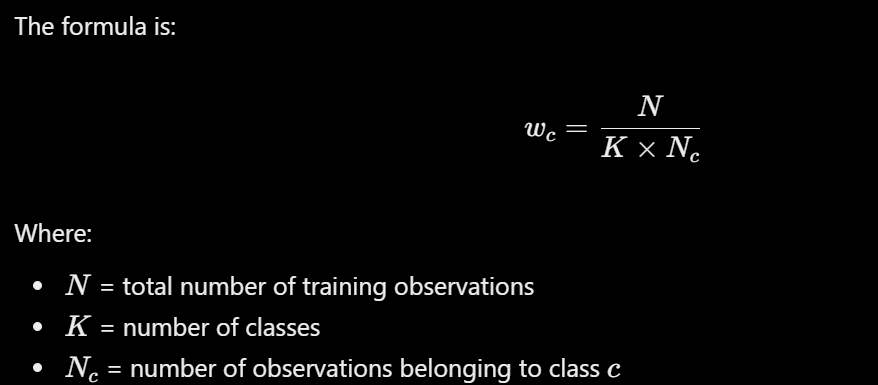

## Algorithms Supporting Class Weight

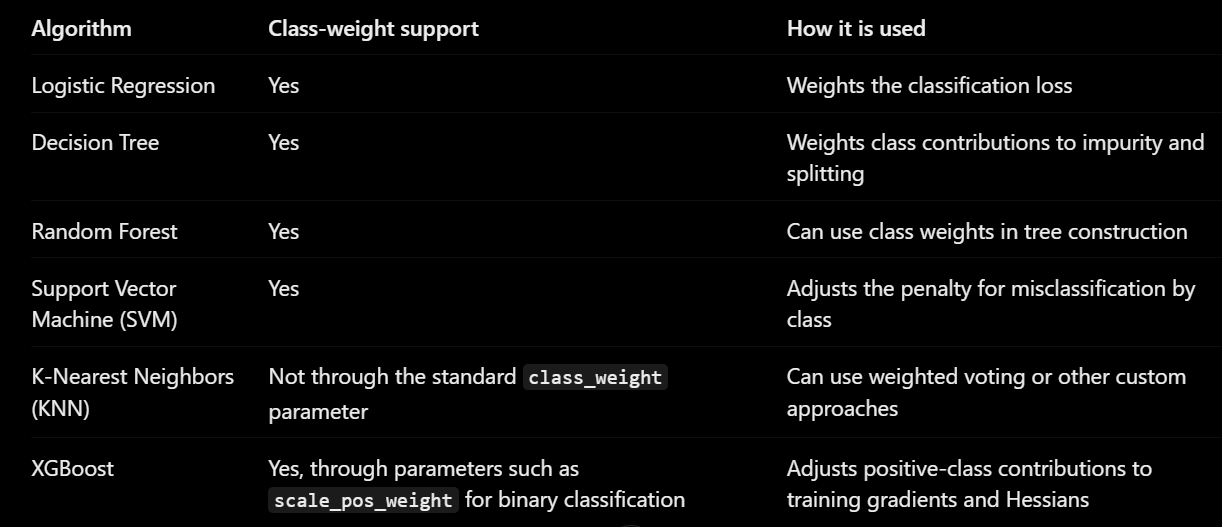

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [45]:
sns.set_theme(style="whitegrid")

In [46]:
# Generate an imbalanced binary classification dataset
X, y = make_classification(
    n_samples=2000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    class_sep=0.8,
    flip_y=0.01,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
df["Target"] = y

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Target"].value_counts().sort_index())
print("\nClass percentages:")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (2000, 3)

Class distribution:
Target
0    1893
1     107
Name: count, dtype: int64

Class percentages:
Target
0    94.65
1     5.35
Name: proportion, dtype: float64


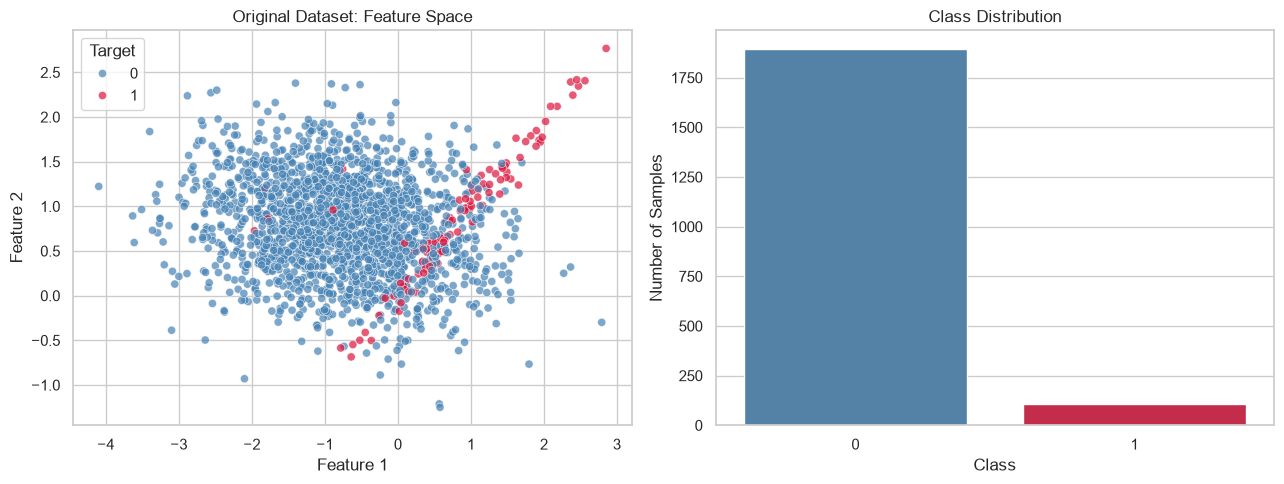

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter plot
sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title("Original Dataset: Feature Space")

# Class counts
sns.countplot(
    data=df,
    x="Target",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

# Baseline Model

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training distribution:
0    1420
1      80
Name: count, dtype: int64

Test distribution:
0    473
1     27
Name: count, dtype: int64


BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

Majority (0)      0.949     0.989     0.969       473
Minority (1)      0.286     0.074     0.118        27

    accuracy                          0.940       500
   macro avg      0.618     0.532     0.543       500
weighted avg      0.913     0.940     0.923       500

Baseline Average Precision: 0.241


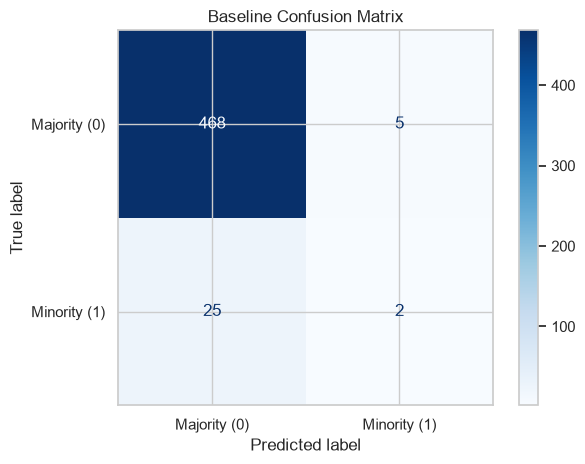

In [58]:
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

baseline_pred = baseline_model.predict(X_test_scaled)
baseline_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("BASELINE CLASSIFICATION REPORT")
print(classification_report(
    y_test, baseline_pred,
    target_names=["Majority (0)", "Minority (1)"],
    digits=3,
    zero_division=0
))

print("Baseline Average Precision:",
      round(average_precision_score(y_test, baseline_proba), 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["Majority (0)", "Minority (1)"],
    cmap="Blues"
)
plt.title("Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

In [49]:
print("Training data shape:", X_train_scaled.shape)
print("Test data shape:", X_test_scaled.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training data shape: (1500, 2)
Test data shape: (500, 2)

Training class distribution:
0    1420
1      80
Name: count, dtype: int64

Test class distribution:
0    473
1     27
Name: count, dtype: int64


# Weighted Model

In [50]:
weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_model.fit(X_train_scaled, y_train)

weighted_pred = weighted_model.predict(X_test_scaled)
weighted_proba = weighted_model.predict_proba(X_test_scaled)[:, 1]

print("Class weights:", weighted_model.class_weight)


Class weights: balanced


In [51]:

print("CLASSIFICATION REPORT — BALANCED LOGISTIC REGRESSION")
print(classification_report(y_test, weighted_pred, digits=3))

print("Accuracy:",
      round(accuracy_score(y_test, weighted_pred), 3))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, weighted_pred), 3))

print("Minority precision:",
      round(precision_score(y_test, weighted_pred, zero_division=0), 3))

print("Minority recall:",
      round(recall_score(y_test, weighted_pred, zero_division=0), 3))

print("Minority F1:",
      round(f1_score(y_test, weighted_pred, zero_division=0), 3))

print("Average precision:",
      round(average_precision_score(y_test, weighted_proba), 3))


CLASSIFICATION REPORT — BALANCED LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0      0.989     0.793     0.880       473
           1      0.190     0.852     0.311        27

    accuracy                          0.796       500
   macro avg      0.590     0.822     0.596       500
weighted avg      0.946     0.796     0.850       500

Accuracy: 0.796
Balanced accuracy: 0.822
Minority precision: 0.19
Minority recall: 0.852
Minority F1: 0.311
Average precision: 0.159


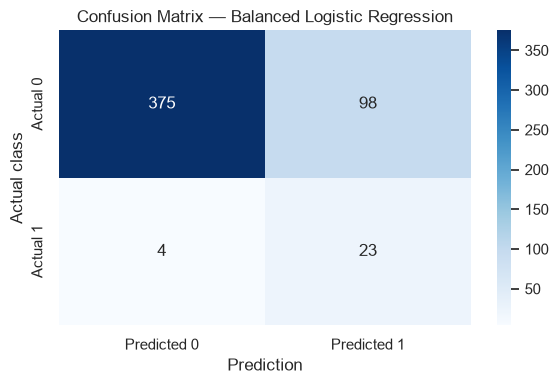

In [52]:

cm = confusion_matrix(y_test, weighted_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Confusion Matrix — Balanced Logistic Regression")
plt.xlabel("Prediction")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()


In [54]:
def evaluate_model(y_true, y_pred, y_proba, name):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Minority Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Minority Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Minority F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_true, y_proba
        )
    }

In [59]:

comparison = pd.DataFrame([
    evaluate_model(
        y_test, baseline_pred, baseline_proba,
        "Baseline Logistic Regression"
    ),
    evaluate_model(
        y_test, weighted_pred, weighted_proba,
        "Balanced Logistic Regression"
    )
]).set_index("Model")

comparison["Balanced Accuracy"] = [
    balanced_accuracy_score(y_test, baseline_pred),
    balanced_accuracy_score(y_test, weighted_pred)
]

display(comparison.round(3))


,Accuracy,Minority Precision,Minority Recall,Minority F1,Average Precision,Balanced Accuracy
Model,,,,,,
Baseline Logistic Regression,0.940,0.286,0.074,0.118,0.241,0.532
Balanced Logistic Regression,0.796,0.190,0.852,0.311,0.159,0.822


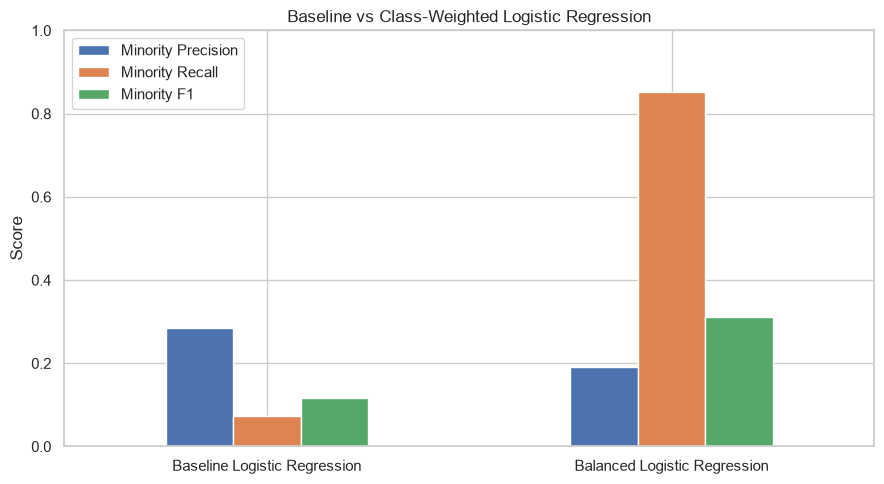

In [60]:

metrics_to_plot = [
    "Minority Precision",
    "Minority Recall",
    "Minority F1"
]

comparison[metrics_to_plot].plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1)
)

plt.title("Baseline vs Class-Weighted Logistic Regression")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()
